# Neighborhood coverage and population check

Compared the `Neighborhood` values in `Neighborhood Transit Access Data.xlsx` (`Equity_Access_Corridor`) with those in `Constituent Bike Lane Survey Results.xlsx` (`Survey_Data`). All eight neighborhoods are present in both files; there are no unmatched names.

The neighborhood populations in the transit-access workbook are:

| Neighborhood | Population |
|:--|--:|
| Downtown | 16,987 |
| East Side | 14,627 |
| Elmwood | 22,129 |
| North End | 21,904 |
| Riverfront | 37,272 |
| South Harbor | 21,699 |
| University District | 10,246 |
| West Side | 9,164 |
| **Total** | **154,028** |

The code below reloads both files, checks neighborhood coverage, and displays the populations alongside survey response counts. Survey counts are not neighborhood population estimates.

In [1]:
from pathlib import Path
import pandas as pd

TRANSIT_FILE = Path.cwd() / "Neighborhood Transit Access Data.xlsx"
SURVEY_FILE = Path.cwd() / "Constituent Bike Lane Survey Results.xlsx"
for path in (TRANSIT_FILE, SURVEY_FILE):
    if not path.exists():
        raise FileNotFoundError(f"Required workbook not found: {path}")

population_data = pd.read_excel(
    TRANSIT_FILE, sheet_name="Equity_Access_Corridor"
)
survey_data = pd.read_excel(
    SURVEY_FILE, sheet_name="Survey_Data", header=1
)

population_data["Neighborhood"] = population_data["Neighborhood"].astype("string").str.strip()
survey_data["Neighborhood"] = survey_data["Neighborhood"].astype("string").str.strip()
population_by_neighborhood = population_data.groupby("Neighborhood")["Population"].sum()
survey_counts = survey_data.groupby("Neighborhood").size().rename("Survey respondents")
population_names = set(population_by_neighborhood.index)
survey_names = set(survey_counts.index)
missing_population = sorted(survey_names - population_names)
missing_survey = sorted(population_names - survey_names)

comparison = pd.concat(
    [population_by_neighborhood.rename("Population"), survey_counts], axis=1
).fillna(0).astype({"Population": "int64", "Survey respondents": "int64"})
comparison = comparison.sort_index()
display(comparison)

print(f"Neighborhoods in population file: {len(population_names)}")
print(f"Neighborhoods in survey file: {len(survey_names)}")
print(f"Total population across listed neighborhoods: {population_by_neighborhood.sum():,.0f}")
print(f"Survey neighborhoods without population data: {missing_population}")
print(f"Population neighborhoods absent from survey: {missing_survey}")

if missing_population or missing_survey:
    raise ValueError("Neighborhood coverage does not match between the two workbooks.")

,Population,Survey respondents
Neighborhood,,
Downtown,16987,66
East Side,14627,60
Elmwood,22129,41
North End,21904,56
Riverfront,37272,42
South Harbor,21699,37
University District,10246,50
West Side,9164,48


Neighborhoods in population file: 8
Neighborhoods in survey file: 8
Total population across listed neighborhoods: 154,028
Survey neighborhoods without population data: []
Population neighborhoods absent from survey: []


## Join survey responses to neighborhood measures

The neighborhood workbook has one record per neighborhood, while the survey has many responses per neighborhood. A left many-to-one join keeps every survey response and adds the matching neighborhood-level measures.

In [2]:
survey_for_join = survey_data.copy()
neighborhood_table = population_data.copy()
survey_for_join["Neighborhood"] = survey_for_join["Neighborhood"].astype("string").str.strip()
neighborhood_table["Neighborhood"] = neighborhood_table["Neighborhood"].astype("string").str.strip()

if neighborhood_table["Neighborhood"].duplicated().any():
    raise ValueError("Neighborhood table must contain one row per neighborhood for a many-to-one join.")

survey_with_neighborhood = survey_for_join.merge(
    neighborhood_table,
    on="Neighborhood",
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("_survey", "_neighborhood"),
)
unmatched_neighborhoods = sorted(
    survey_with_neighborhood.loc[
        survey_with_neighborhood["_merge"].ne("both"), "Neighborhood"
    ].dropna().unique().tolist()
)
if len(survey_with_neighborhood) != len(survey_data):
    raise ValueError("The neighborhood join changed the number of survey responses.")
if unmatched_neighborhoods:
    raise ValueError(f"Survey neighborhoods missing from neighborhood table: {unmatched_neighborhoods}")

survey_with_neighborhood = survey_with_neighborhood.drop(columns="_merge")
print(f"Joined {len(survey_with_neighborhood)} survey responses to neighborhood measures.")
print(f"Unique matched neighborhoods: {survey_with_neighborhood['Neighborhood'].nunique()}")
display(survey_with_neighborhood.head())

Joined 400 survey responses to neighborhood measures.
Unique matched neighborhoods: 8


,Respondent_ID,Survey_Date,Ward,Neighborhood,Race_Ethnicity,Age,Age_Group,Occupation,Bike_Rider_Frequency,Bike_Rider,...,Top_Reason_or_Concern,Open_Ended_Response,Interview_Mode,Median_Income,Pct_Minority,Pct_No_Car,Avg_Commute_Time,Transit_Access_Score,Bike_Lane_Access,Population
0,BLS-088,2026-02-18,Ward 8,University District,Asian,37,30-44,Small Business Owner,Weekly,Yes,...,Safer for cyclists,This would help people bike without having to ...,Phone,80196,45,6,42,10,Low,10246
1,BLS-115,2026-02-18,Ward 8,University District,Hispanic/Latino,37,30-44,Office/Admin,Never,No,...,Wants loading zones protected,NaN,Online,80196,45,6,42,10,Low,10246
2,BLS-155,2026-02-18,Ward 1,Downtown,White,27,18-29,Service/Hospitality,Weekly,Yes,...,Better for kids and families,NaN,Phone,73437,55,29,56,10,Low,16987
3,BLS-156,2026-02-18,Ward 7,Elmwood,White,51,45-59,Teacher/School Staff,Never,No,...,Needs stronger intersection design,NaN,Phone,119723,49,32,21,8,High,22129
4,BLS-183,2026-02-18,Ward 7,Elmwood,White,40,30-44,Tech/Professional,Rarely,Yes,...,Wants loading zones protected,NaN,Online,119723,49,32,21,8,High,22129


## Unit and scale validation

The workbook has one data sheet and no data dictionary, field descriptions, cell comments, or unit-bearing number formats. Numeric ranges can be checked, but they cannot substitute for missing source definitions.

| Field | What the file supports | Validation status |
|:--|:--|:--|
| `Median_Income` | Values range from 42,777 to 119,723. | Currency, reference year, and whether the median is for individuals or households are not specified. Do not label as USD/year without source confirmation. |
| `Pct_Minority`, `Pct_No_Car` | Names indicate percentages; stored values range from 6 to 81. | Values are on a 0–100 percentage scale, not 0–1 fractions. The population/household denominator and definition of each measure are not specified. |
| `Avg_Commute_Time` | Values range from 21 to 56. | Unit and commute definition are not specified. Minutes may be plausible, but cannot be confirmed from this workbook. |
| `Transit_Access_Score` | Integer values range from 3 to 10. | It is a score, but scale bounds, method, and whether higher means better access are not specified. Do not assume a 0–10 or 1–10 scale. |

Before labeling charts or comparing these measures to external data, obtain the source data dictionary or confirmation from the data provider.

In [3]:
unit_fields = [
    "Median_Income",
    "Pct_Minority",
    "Pct_No_Car",
    "Avg_Commute_Time",
    "Transit_Access_Score",
]
numeric_fields = population_data[unit_fields].apply(pd.to_numeric, errors="raise")
if numeric_fields.isna().any().any():
    raise ValueError("A unit-check field contains missing values.")

percentage_fields = ["Pct_Minority", "Pct_No_Car"]
invalid_percentages = {
    field: numeric_fields.loc[~numeric_fields[field].between(0, 100), field].tolist()
    for field in percentage_fields
}
invalid_percentages = {field: values for field, values in invalid_percentages.items() if values}
if invalid_percentages:
    raise ValueError(f"Percentage values fall outside 0-100: {invalid_percentages}")

unit_check = pd.DataFrame({
    "Observed minimum": numeric_fields.min(),
    "Observed maximum": numeric_fields.max(),
})
display(unit_check)
print("Percentage fields are within 0-100; other physical units and the score scale remain undocumented.")

,Observed minimum,Observed maximum
Median_Income,42777,119723
Pct_Minority,30,81
Pct_No_Car,6,44
Avg_Commute_Time,21,56
Transit_Access_Score,3,10


Percentage fields are within 0-100; other physical units and the score scale remain undocumented.


## Neighborhood comparison

The table compares all eight neighborhoods across the requested fields. Separate small-multiple charts compare numeric values without combining unlike scales. `Bike_Lane_Access` is kept categorical. Income currency/period, commute-time units, and transit-score scale remain unspecified in the source workbook; percentage denominators are also undocumented.

| Neighborhood | Bike-lane access | Transit score* | Commute time* | Without car (%) | Median income* | Minority (%) | Population |
|:--|:--|--:|--:|--:|--:|--:|--:|
| Downtown | Low | 10 | 56 | 29 | 73,437 | 55 | 16,987 |
| East Side | High | 10 | 52 | 8 | 54,689 | 65 | 14,627 |
| Elmwood | High | 8 | 21 | 32 | 119,723 | 49 | 22,129 |
| North End | Medium | 4 | 54 | 32 | 54,872 | 62 | 21,904 |
| Riverfront | Low | 10 | 50 | 11 | 42,777 | 30 | 37,272 |
| South Harbor | High | 7 | 34 | 44 | 53,989 | 81 | 21,699 |
| University District | Low | 10 | 42 | 6 | 80,196 | 45 | 10,246 |
| West Side | High | 3 | 44 | 30 | 73,194 | 77 | 9,164 |

*Transit score scale, commute-time unit, and income currency/period are unspecified in the source. Percentage denominators and definitions are also undocumented.

In [4]:
comparison_fields = [
    "Neighborhood",
    "Bike_Lane_Access",
    "Transit_Access_Score",
    "Avg_Commute_Time",
    "Pct_No_Car",
    "Median_Income",
    "Pct_Minority",
    "Population",
]
if population_data["Neighborhood"].duplicated().any():
    raise ValueError("Expected one row per neighborhood in the transit workbook.")

neighborhood_comparison = population_data[comparison_fields].set_index("Neighborhood").sort_index()
neighborhood_comparison = neighborhood_comparison.rename(columns={
    "Bike_Lane_Access": "Bike-lane access",
    "Transit_Access_Score": "Transit-access score (scale unspecified)",
    "Avg_Commute_Time": "Average commute time (unit unspecified)",
    "Pct_No_Car": "Without car (%)",
    "Median_Income": "Median income (currency/period unspecified)",
    "Pct_Minority": "Minority population (%)",
    "Population": "Total population",
})
display(neighborhood_comparison.style.format({
    "Transit-access score (scale unspecified)": "{:.0f}",
    "Average commute time (unit unspecified)": "{:.0f}",
    "Without car (%)": "{:.0f}%",
    "Median income (currency/period unspecified)": "{:,.0f}",
    "Minority population (%)": "{:.0f}%",
    "Total population": "{:,.0f}",
}))

,Bike-lane access,Transit-access score (scale unspecified),Average commute time (unit unspecified),Without car (%),Median income (currency/period unspecified),Minority population (%),Total population
Neighborhood,,,,,,,
Downtown,Low,10,56,29%,"73,437",55%,"16,987"
East Side,High,10,52,8%,"54,689",65%,"14,627"
Elmwood,High,8,21,32%,"119,723",49%,"22,129"
North End,Medium,4,54,32%,"54,872",62%,"21,904"
Riverfront,Low,10,50,11%,"42,777",30%,"37,272"
South Harbor,High,7,34,44%,"53,989",81%,"21,699"
University District,Low,10,42,6%,"80,196",45%,"10,246"
West Side,High,3,44,30%,"73,194",77%,"9,164"


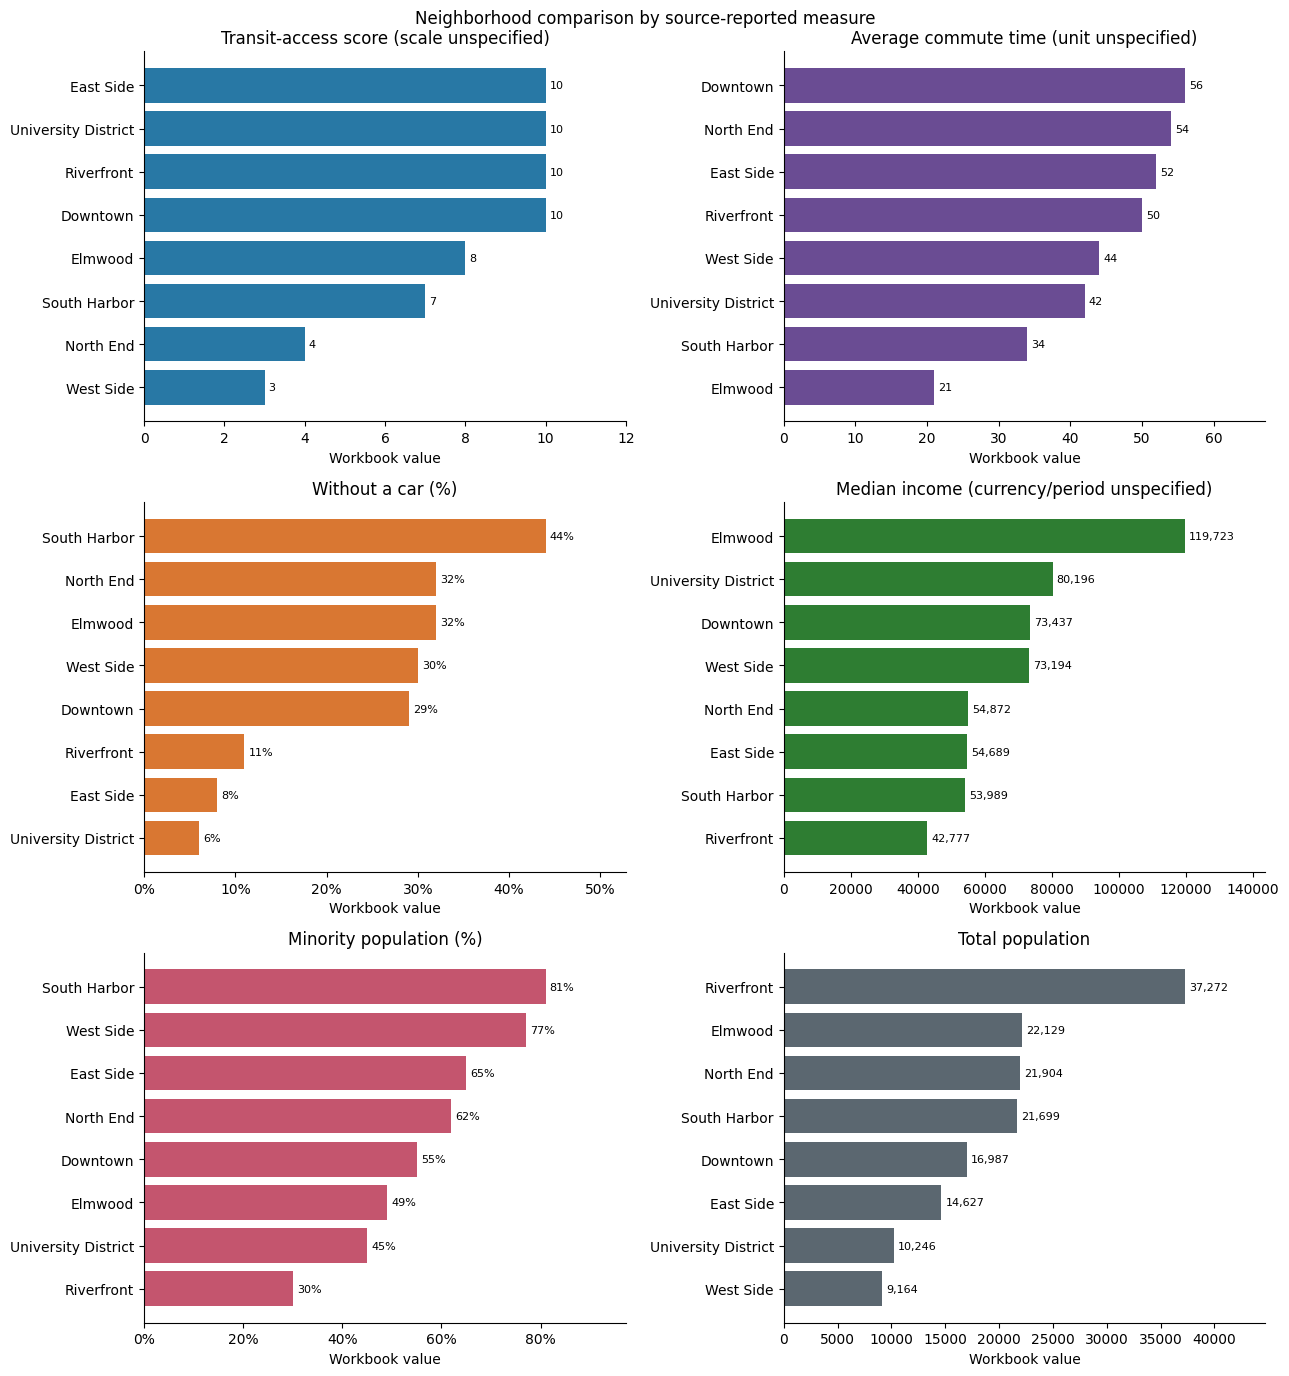

In [5]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

numeric_comparisons = [
    ("Transit_Access_Score", "Transit-access score (scale unspecified)", "#2878A5", "number"),
    ("Avg_Commute_Time", "Average commute time (unit unspecified)", "#6A4C93", "number"),
    ("Pct_No_Car", "Without a car (%)", "#D97732", "percent"),
    ("Median_Income", "Median income (currency/period unspecified)", "#2E7D32", "integer"),
    ("Pct_Minority", "Minority population (%)", "#C4556E", "percent"),
    ("Population", "Total population", "#5B6770", "integer"),
]
fig, axes = plt.subplots(3, 2, figsize=(13, 14))
neighborhood_indexed = population_data.set_index("Neighborhood")
for ax, (field, title, color, value_format) in zip(axes.flat, numeric_comparisons):
    values = pd.to_numeric(neighborhood_indexed[field], errors="raise").sort_values()
    bars = ax.barh(values.index, values.values, color=color)
    if value_format == "percent":
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
        labels = [f"{value:.0f}%" for value in values.values]
    elif value_format == "integer":
        labels = [f"{value:,.0f}" for value in values.values]
    else:
        labels = [f"{value:g}" for value in values.values]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
    ax.set_xlim(0, values.max() * 1.2)
    ax.set_title(title)
    ax.set_xlabel("Workbook value")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Neighborhood comparison by source-reported measure")
fig.tight_layout()
plt.show()

## Low bike-lane access and potential transit need

For a transparent screen, treat the workbook's `Low` bike-lane-access category as low access. Use a higher-than-average share without a car and a longer-than-average commute as descriptive transit-need proxies. The averages below weight each neighborhood equally; they are not population-weighted thresholds or a validated need index.

**Downtown is the clearest overlap:** it has low bike-lane access, the highest average commute time (56, versus an eight-neighborhood mean of 44.1), and an above-mean no-car share (29%, versus 24%). **Riverfront** also has low access and a longer-than-average commute (50), but its no-car share is below the mean (11%). **University District** has low access, but its no-car share (6%) and commute time (42) are both below their respective means.

The transit-access score is not used to judge need: the workbook does not document its scale or whether a higher score means better or worse access. These comparisons identify places to investigate, not proof of unmet need.

In [6]:
need_data = population_data.copy()
need_data["Avg_Commute_Time"] = pd.to_numeric(need_data["Avg_Commute_Time"], errors="raise")
need_data["Pct_No_Car"] = pd.to_numeric(need_data["Pct_No_Car"], errors="raise")
mean_commute = need_data["Avg_Commute_Time"].mean()
mean_no_car = need_data["Pct_No_Car"].mean()

low_access_need = need_data.loc[
    need_data["Bike_Lane_Access"].astype("string").str.strip().str.casefold().eq("low"),
    ["Neighborhood", "Bike_Lane_Access", "Pct_No_Car", "Avg_Commute_Time", "Population"],
].copy()
low_access_need["No-car share above neighborhood mean"] = low_access_need["Pct_No_Car"] > mean_no_car
low_access_need["Commute above neighborhood mean"] = low_access_need["Avg_Commute_Time"] > mean_commute
low_access_need = low_access_need.rename(columns={
    "Bike_Lane_Access": "Bike-lane access",
    "Pct_No_Car": "Without car (%)",
    "Avg_Commute_Time": "Average commute time (unit unspecified)",
    "Population": "Total population",
})
print(f"Neighborhood-average no-car share: {mean_no_car:.1f}%")
print(f"Neighborhood-average commute value (unit unspecified): {mean_commute:.1f}")
display(low_access_need.sort_values("Neighborhood").style.format({
    "Without car (%)": "{:.0f}%",
    "Average commute time (unit unspecified)": "{:.0f}",
    "Total population": "{:,.0f}",
}))

Neighborhood-average no-car share: 24.0%
Neighborhood-average commute value (unit unspecified): 44.1


,Neighborhood,Bike-lane access,Without car (%),Average commute time (unit unspecified),Total population,No-car share above neighborhood mean,Commute above neighborhood mean
0,Downtown,Low,29%,56,"16,987",True,True
4,Riverfront,Low,11%,50,"37,272",False,True
5,University District,Low,6%,42,"10,246",False,False


## Potential equity gaps if communities are outside the proposal

The workbook does not map the proposed route to neighborhoods, so it cannot identify which communities are actually served or left out. `Bike_Lane_Access` describes an access category, not whether the proposed project serves that neighborhood. The findings below are therefore a screening list, conditional on route coverage.

Using the eight-neighborhood medians as a simple relative screen, the larger communities are Riverfront (37,272), Elmwood (22,129), North End (21,904), and South Harbor (21,699). The lower-income half by the recorded `Median_Income` values is Riverfront (42,777), South Harbor (53,989), East Side (54,689), and North End (54,872). These are relative comparisons only; the workbook does not specify income currency, period, or unit of analysis.

- **Riverfront is the strongest potential equity-gap candidate if unserved:** it is the largest and lowest-income neighborhood, and its bike-lane access category is Low.
- **North End is also a potential priority if unserved:** it is among the larger and lower-income neighborhoods, has Medium bike-lane access, 32% without a car, and a commute value of 54 (time unit unspecified).
- **South Harbor warrants an access and coverage check:** it is among the larger and lower-income neighborhoods and has the highest no-car share (44%) and minority share (81%), although its existing bike-lane-access category is High.
- **East Side is in the lower-income half but is smaller and has High bike-lane access;** its no-car share is 8%.

These data can prioritize route-coverage review, but cannot establish that any of these neighborhoods is excluded. Confirm against a project map or an authoritative neighborhood-to-route list before describing an actual service gap.

In [7]:
equity_data = population_data.copy()
for field in ["Population", "Median_Income", "Pct_No_Car", "Pct_Minority", "Avg_Commute_Time"]:
    equity_data[field] = pd.to_numeric(equity_data[field], errors="raise")

population_median = equity_data["Population"].median()
income_median = equity_data["Median_Income"].median()
equity_data["Larger community (at/above population median)"] = equity_data["Population"] >= population_median
equity_data["Lower-income half (at/below income median)"] = equity_data["Median_Income"] <= income_median
screened = equity_data.loc[
    equity_data["Larger community (at/above population median)"]
    | equity_data["Lower-income half (at/below income median)"],
    [
        "Neighborhood", "Bike_Lane_Access", "Population", "Median_Income",
        "Pct_No_Car", "Pct_Minority", "Avg_Commute_Time",
        "Larger community (at/above population median)",
        "Lower-income half (at/below income median)",
    ],
].sort_values(
    ["Lower-income half (at/below income median)", "Larger community (at/above population median)", "Population"],
    ascending=[False, False, False],
)
screened = screened.rename(columns={
    "Bike_Lane_Access": "Bike-lane access",
    "Population": "Population",
    "Median_Income": "Median income (unit unspecified)",
    "Pct_No_Car": "Without car (%)",
    "Pct_Minority": "Minority share (%)",
    "Avg_Commute_Time": "Commute value (unit unspecified)",
})
print(f"Population median: {population_median:,.0f}; recorded-income median: {income_median:,.0f} (unit unspecified)")
display(screened.style.format({
    "Population": "{:,.0f}",
    "Median income (unit unspecified)": "{:,.0f}",
    "Without car (%)": "{:.0f}%",
    "Minority share (%)": "{:.0f}%",
    "Commute value (unit unspecified)": "{:.0f}",
}))

Population median: 19,343; recorded-income median: 64,033 (unit unspecified)


,Neighborhood,Bike-lane access,Population,Median income (unit unspecified),Without car (%),Minority share (%),Commute value (unit unspecified),Larger community (at/above population median),Lower-income half (at/below income median)
4,Riverfront,Low,"37,272","42,777",11%,30%,50,True,True
2,North End,Medium,"21,904","54,872",32%,62%,54,True,True
3,South Harbor,High,"21,699","53,989",44%,81%,34,True,True
6,East Side,High,"14,627","54,689",8%,65%,52,False,True
1,Elmwood,High,"22,129","119,723",32%,49%,21,True,False


## Local need indicators and surveyed public support

Need indicators and survey opinion are compared side by side, not combined into a score. Need is represented by the source-reported bike-lane-access category, no-car share, commute value, income, and population. Public support is the share of survey respondents in each neighborhood selecting Support; Undecided and Oppose shares are shown separately. These are sample responses, not a population-wide vote.

The pattern is not a simple need-to-support relationship. **South Harbor** has the highest no-car share (44%) and minority share (81%), but the lowest support (29.7%) and highest opposition (37.8%; n=37). **Riverfront** is the largest, lowest-income, Low-access neighborhood, yet support is 47.6%, with 40.5% undecided and 11.9% opposed (n=42). **North End** has 32% without a car and a commute value of 54; support is 53.6%, with 28.6% opposed (n=56). Meanwhile, **Downtown** has Low bike-lane access and the longest commute value (56), alongside 65.2% support (n=66). These contrasts show why need should not be treated as evidence of support.

In [8]:
opinion_order = ["Support", "Undecided", "Oppose"]
opinion_counts = pd.crosstab(
    survey_with_neighborhood["Neighborhood"],
    survey_with_neighborhood["Support_for_New_Bike_Lane"],
).reindex(columns=opinion_order, fill_value=0)
respondent_totals = opinion_counts.sum(axis=1)
opinion_summary = opinion_counts.copy()
for opinion in opinion_order:
    opinion_summary[f"{opinion} %"] = opinion_counts[opinion].div(respondent_totals).mul(100)
opinion_summary = opinion_summary.rename(columns={
    "Support": "Support n",
    "Undecided": "Undecided n",
    "Oppose": "Oppose n",
})
opinion_summary["Survey respondents"] = respondent_totals
opinion_summary = opinion_summary.reset_index()

local_need_and_support = population_data.merge(
    opinion_summary, on="Neighborhood", how="left", validate="one_to_one"
)
if local_need_and_support["Survey respondents"].isna().any():
    raise ValueError("A neighborhood has no matched survey opinion summary.")

display_columns = [
    "Neighborhood", "Bike_Lane_Access", "Pct_No_Car", "Avg_Commute_Time",
    "Median_Income", "Pct_Minority", "Population", "Survey respondents",
    "Support %", "Undecided %", "Oppose %",
]
local_need_and_support = local_need_and_support.sort_values("Neighborhood")
display(local_need_and_support[display_columns].rename(columns={
    "Bike_Lane_Access": "Bike-lane access",
    "Pct_No_Car": "Without car (%)",
    "Avg_Commute_Time": "Commute value (unit unspecified)",
    "Median_Income": "Median income (unit unspecified)",
    "Pct_Minority": "Minority share (%)",
    "Population": "Population",
}).style.format({
    "Without car (%)": "{:.0f}%",
    "Commute value (unit unspecified)": "{:.0f}",
    "Median income (unit unspecified)": "{:,.0f}",
    "Minority share (%)": "{:.0f}%",
    "Population": "{:,.0f}",
    "Support %": "{:.1f}%",
    "Undecided %": "{:.1f}%",
    "Oppose %": "{:.1f}%",
}))

,Neighborhood,Bike-lane access,Without car (%),Commute value (unit unspecified),Median income (unit unspecified),Minority share (%),Population,Survey respondents,Support %,Undecided %,Oppose %
0,Downtown,Low,29%,56,"73,437",55%,"16,987",66,65.2%,22.7%,12.1%
6,East Side,High,8%,52,"54,689",65%,"14,627",60,58.3%,20.0%,21.7%
1,Elmwood,High,32%,21,"119,723",49%,"22,129",41,41.5%,24.4%,34.1%
2,North End,Medium,32%,54,"54,872",62%,"21,904",56,53.6%,17.9%,28.6%
4,Riverfront,Low,11%,50,"42,777",30%,"37,272",42,47.6%,40.5%,11.9%
3,South Harbor,High,44%,34,"53,989",81%,"21,699",37,29.7%,32.4%,37.8%
5,University District,Low,6%,42,"80,196",45%,"10,246",50,64.0%,30.0%,6.0%
7,West Side,High,30%,44,"73,194",77%,"9,164",48,41.7%,27.1%,31.2%


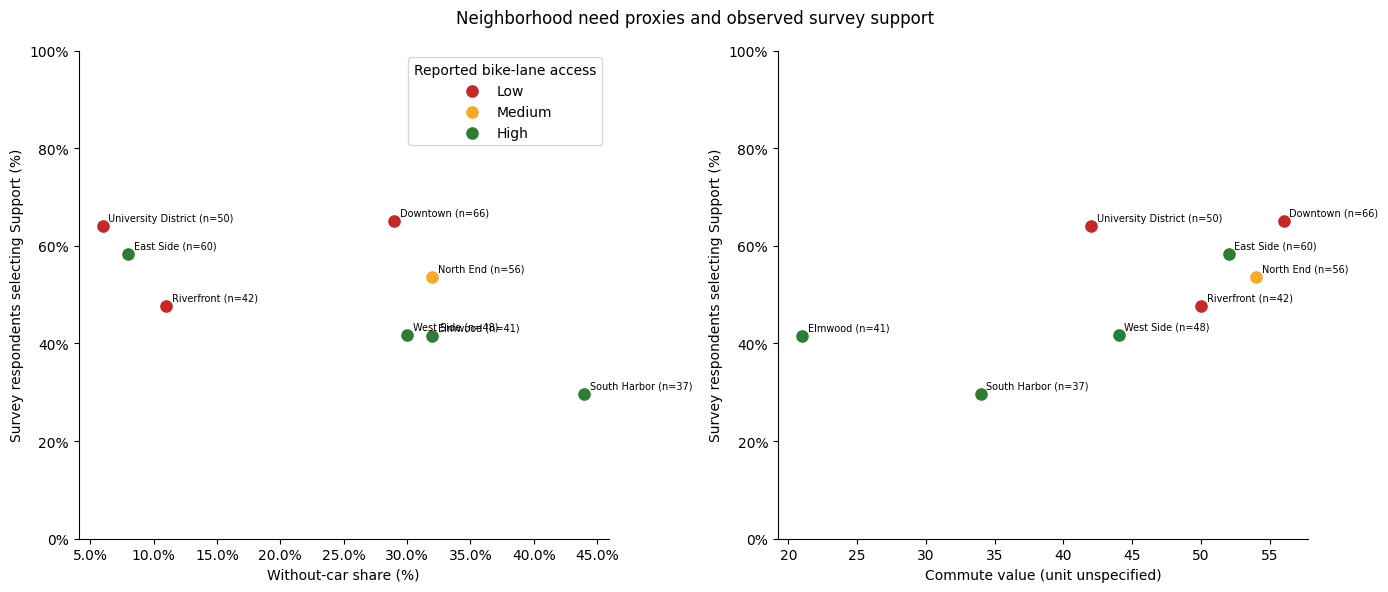

Descriptive comparison only; the plot does not imply that need causes support.


In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plot_data = local_need_and_support.copy()
plot_data["Pct_No_Car"] = pd.to_numeric(plot_data["Pct_No_Car"], errors="raise")
plot_data["Avg_Commute_Time"] = pd.to_numeric(plot_data["Avg_Commute_Time"], errors="raise")
plot_data["Support %"] = pd.to_numeric(plot_data["Support %"], errors="raise")
access_colors = {"Low": "#C62828", "Medium": "#F9A825", "High": "#2E7D32"}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, need_field, x_label in zip(
    axes,
    ["Pct_No_Car", "Avg_Commute_Time"],
    ["Without-car share (%)", "Commute value (unit unspecified)"],
):
    for access_level, color in access_colors.items():
        group = plot_data.loc[plot_data["Bike_Lane_Access"].eq(access_level)]
        ax.scatter(group[need_field], group["Support %"], color=color, label=access_level, s=65)
    for _, row in plot_data.iterrows():
        ax.annotate(
            f"{row['Neighborhood']} (n={int(row['Survey respondents'])})",
            (row[need_field], row["Support %"]),
            xytext=(4, 4), textcoords="offset points", fontsize=7,
        )
    ax.set_xlabel(x_label)
    ax.set_ylabel("Survey respondents selecting Support (%)")
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    if need_field == "Pct_No_Car":
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(title="Reported bike-lane access")
fig.suptitle("Neighborhood need proxies and observed survey support")
fig.tight_layout()
plt.show()
print("Descriptive comparison only; the plot does not imply that need causes support.")

## Exploratory route-priority matrix

This is a neighborhood-level screening matrix, not a mapped route plan. The workbooks do not identify which neighborhoods the proposed route serves.

For an explicit, reproducible screen, **high need** means meeting at least two of three indicators: Bike_Lane_Access is Low or Medium; no-car share is above the eight-neighborhood median; commute value is above the eight-neighborhood median. **High support** means neighborhood survey support is at least the overall respondent support rate (52%). Median income, population, and minority share remain visible as equity context, but are not added to the need score. Changing these thresholds can change assignments.

| Need and support quadrant | Neighborhoods |
|:--|:--|
| High need, high support | Downtown; North End |
| High need, low support | Riverfront |
| Low need, high support | East Side; University District |
| Low need, low support | Elmwood; South Harbor; West Side |

Interpretation: high-need/high-support areas may be stronger near-term candidates. High-need/low-support areas should prompt additional engagement and design review, not automatic deprioritization. Low-need/high-support areas may offer opportunities when they strengthen network connections. Low-need/low-support areas are lower priority under this screen, subject to other project goals.

In [10]:
priority = local_need_and_support.copy()
priority["Pct_No_Car"] = pd.to_numeric(priority["Pct_No_Car"], errors="raise")
priority["Avg_Commute_Time"] = pd.to_numeric(priority["Avg_Commute_Time"], errors="raise")
priority["Median_Income"] = pd.to_numeric(priority["Median_Income"], errors="raise")
priority["Population"] = pd.to_numeric(priority["Population"], errors="raise")
priority["Bike-access gap indicator"] = priority["Bike_Lane_Access"].astype("string").str.strip().str.casefold().isin(["low", "medium"])
priority["Higher no-car-share indicator"] = priority["Pct_No_Car"] > priority["Pct_No_Car"].median()
priority["Longer-commute indicator"] = priority["Avg_Commute_Time"] > priority["Avg_Commute_Time"].median()
priority["Need indicators met"] = priority[[
    "Bike-access gap indicator",
    "Higher no-car-share indicator",
    "Longer-commute indicator",
]].sum(axis=1)
priority["Need category"] = priority["Need indicators met"].ge(2).map({True: "High need", False: "Low need"})
overall_support_rate = survey_data["Support_for_New_Bike_Lane"].eq("Support").mean() * 100
priority["Support category"] = priority["Support %"].ge(overall_support_rate).map({True: "High support", False: "Low support"})
priority["Priority quadrant"] = priority["Need category"] + ", " + priority["Support category"]
priority["Priority quadrant"] = priority["Priority quadrant"].replace({
    "High need, High support": "High need, high support",
    "High need, Low support": "High need, low support",
    "Low need, High support": "Low need, high support",
    "Low need, Low support": "Low need, low support",
})
priority["Priority quadrant"] = pd.Categorical(priority["Priority quadrant"], categories=[
    "High need, high support", "High need, low support",
    "Low need, high support", "Low need, low support",
], ordered=True)
priority = priority.sort_values(["Priority quadrant", "Neighborhood"])
print(f"Overall survey support reference: {overall_support_rate:.1f}%")
print(f"No-car share median: {priority['Pct_No_Car'].median():.1f}%; commute-value median: {priority['Avg_Commute_Time'].median():.1f} (unit unspecified)")
display(priority[[
    "Neighborhood", "Priority quadrant", "Need indicators met", "Bike_Lane_Access",
    "Pct_No_Car", "Avg_Commute_Time", "Support %", "Undecided %", "Oppose %",
    "Survey respondents", "Population", "Median_Income",
]].rename(columns={
    "Bike_Lane_Access": "Bike-lane access",
    "Pct_No_Car": "Without car (%)",
    "Avg_Commute_Time": "Commute value (unit unspecified)",
    "Support %": "Support (%)",
    "Undecided %": "Undecided (%)",
    "Oppose %": "Oppose (%)",
    "Survey respondents": "Survey n",
    "Median_Income": "Median income (unit unspecified)",
}).style.format({
    "Without car (%)": "{:.0f}%",
    "Commute value (unit unspecified)": "{:.0f}",
    "Support (%)": "{:.1f}%",
    "Undecided (%)": "{:.1f}%",
    "Oppose (%)": "{:.1f}%",
    "Population": "{:,.0f}",
    "Median income (unit unspecified)": "{:,.0f}",
}))

Overall survey support reference: 52.0%
No-car share median: 29.5%; commute-value median: 47.0 (unit unspecified)


,Neighborhood,Priority quadrant,Need indicators met,Bike-lane access,Without car (%),Commute value (unit unspecified),Support (%),Undecided (%),Oppose (%),Survey n,Population,Median income (unit unspecified)
0,Downtown,"High need, high support",2,Low,29%,56,65.2%,22.7%,12.1%,66,"16,987","73,437"
2,North End,"High need, high support",3,Medium,32%,54,53.6%,17.9%,28.6%,56,"21,904","54,872"
4,Riverfront,"High need, low support",2,Low,11%,50,47.6%,40.5%,11.9%,42,"37,272","42,777"
6,East Side,"Low need, high support",1,High,8%,52,58.3%,20.0%,21.7%,60,"14,627","54,689"
5,University District,"Low need, high support",1,Low,6%,42,64.0%,30.0%,6.0%,50,"10,246","80,196"
1,Elmwood,"Low need, low support",1,High,32%,21,41.5%,24.4%,34.1%,41,"22,129","119,723"
3,South Harbor,"Low need, low support",1,High,44%,34,29.7%,32.4%,37.8%,37,"21,699","53,989"
7,West Side,"Low need, low support",1,High,30%,44,41.7%,27.1%,31.2%,48,"9,164","73,194"


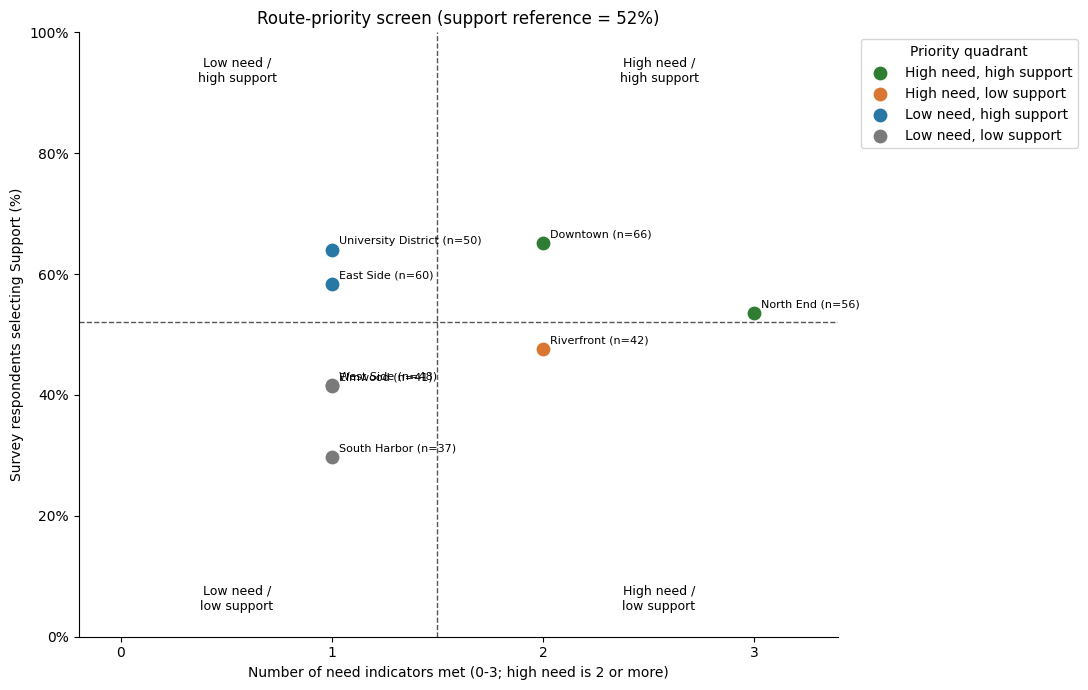

In [11]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

quadrant_colors = {
    "High need, high support": "#2E7D32",
    "High need, low support": "#D97732",
    "Low need, high support": "#2878A5",
    "Low need, low support": "#7A7A7A",
}
fig, ax = plt.subplots(figsize=(11, 7))
for quadrant, color in quadrant_colors.items():
    group = priority.loc[priority["Priority quadrant"].eq(quadrant)]
    ax.scatter(group["Need indicators met"], group["Support %"], color=color, s=80, label=quadrant)
    for _, row in group.iterrows():
        ax.annotate(
            f"{row['Neighborhood']} (n={int(row['Survey respondents'])})",
            (row["Need indicators met"], row["Support %"]),
            xytext=(5, 4), textcoords="offset points", fontsize=8,
        )
ax.axvline(1.5, color="#555555", linestyle="--", linewidth=1)
ax.axhline(overall_support_rate, color="#555555", linestyle="--", linewidth=1)
ax.text(2.55, 96, "High need /\nhigh support", ha="center", va="top", fontsize=9)
ax.text(2.55, 4, "High need /\nlow support", ha="center", va="bottom", fontsize=9)
ax.text(0.55, 96, "Low need /\nhigh support", ha="center", va="top", fontsize=9)
ax.text(0.55, 4, "Low need /\nlow support", ha="center", va="bottom", fontsize=9)
ax.set_xlim(-0.2, 3.4)
ax.set_ylim(0, 100)
ax.set_xticks([0, 1, 2, 3])
ax.set_xlabel("Number of need indicators met (0-3; high need is 2 or more)")
ax.set_ylabel("Survey respondents selecting Support (%)")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.legend(title="Priority quadrant", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Route-priority screen (support reference = {overall_support_rate:.0f}%)")
fig.tight_layout()
plt.show()

## Population by existing bike-lane-access category

These totals group neighborhood populations by the workbook's existing `Bike_Lane_Access` label. They are not estimates of population served by the proposal.

,Neighborhoods,Neighborhood_count,Population,Population share (%)
Bike_Lane_Access,,,,
Low,"Downtown, Riverfront, University District",3,"64,505",41.9%
Medium,North End,1,"21,904",14.2%
High,"East Side, Elmwood, South Harbor, West Side",4,"67,619",43.9%


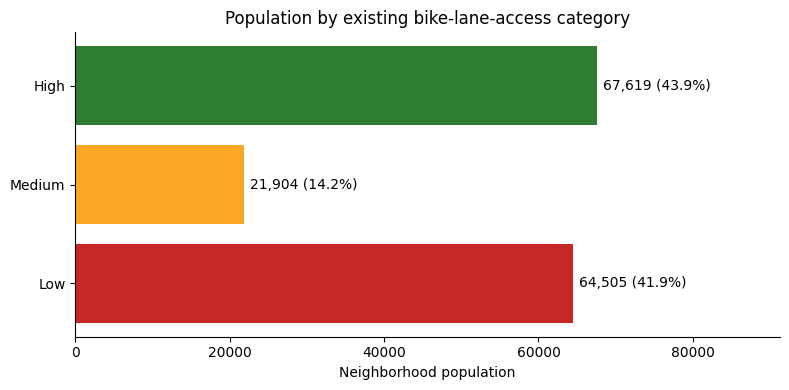

In [12]:
access_population = (
    population_data.groupby("Bike_Lane_Access")
    .agg(
        Neighborhoods=("Neighborhood", lambda values: ", ".join(sorted(values))),
        Neighborhood_count=("Neighborhood", "nunique"),
        Population=("Population", "sum"),
    )
)
total_population = population_data["Population"].sum()
access_population["Population share (%)"] = access_population["Population"] / total_population * 100
access_order = [category for category in ["Low", "Medium", "High"] if category in access_population.index]
access_population = access_population.reindex(access_order)
display(access_population.style.format({
    "Neighborhood_count": "{:,.0f}",
    "Population": "{:,.0f}",
    "Population share (%)": "{:.1f}%",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(access_population.index, access_population["Population"],
               color=[{"Low": "#C62828", "Medium": "#F9A825", "High": "#2E7D32"}[x] for x in access_population.index])
labels = [
    f"{population:,.0f} ({share:.1f}%)"
    for population, share in zip(access_population["Population"], access_population["Population share (%)"])
]
ax.bar_label(bars, labels=labels, padding=4)
ax.set_xlim(0, access_population["Population"].max() * 1.35)
ax.set_xlabel("Neighborhood population")
ax.set_title("Population by existing bike-lane-access category")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## Route-coverage map annotation

The provided workbooks contain no neighborhood boundaries, coordinates, proposed branch geometry, or branch-to-neighborhood assignments. Therefore a geographic coverage map cannot be drawn or annotated without additional source data. The graphic below is a **non-geographic data-gap annotation**, not a map; proposed coverage is marked unknown rather than inferred from existing bike-lane access.

,Neighborhood,Existing bike-lane access,Population,Proposed route coverage
0,Downtown,Low,16987,Unknown — branch mapping not provided
6,East Side,High,14627,Unknown — branch mapping not provided
1,Elmwood,High,22129,Unknown — branch mapping not provided
2,North End,Medium,21904,Unknown — branch mapping not provided
4,Riverfront,Low,37272,Unknown — branch mapping not provided
3,South Harbor,High,21699,Unknown — branch mapping not provided
5,University District,Low,10246,Unknown — branch mapping not provided
7,West Side,High,9164,Unknown — branch mapping not provided


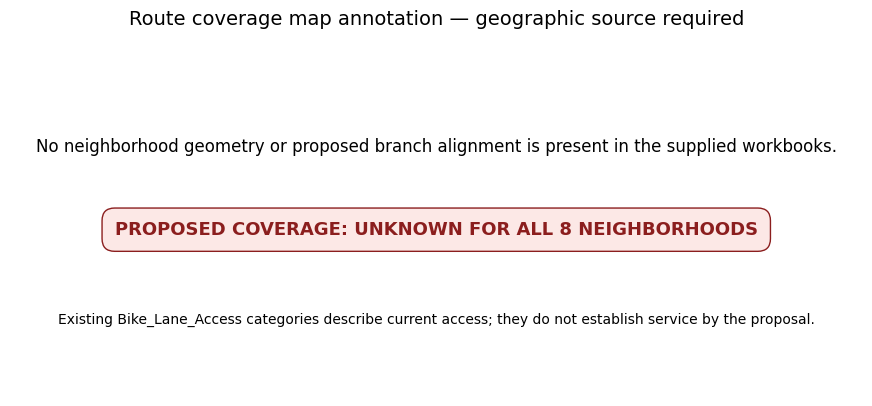

In [13]:
coverage_status = population_data[["Neighborhood", "Bike_Lane_Access", "Population"]].copy()
coverage_status["Proposed route coverage"] = "Unknown — branch mapping not provided"
display(coverage_status.sort_values("Neighborhood").rename(columns={
    "Bike_Lane_Access": "Existing bike-lane access",
    "Population": "Population",
}))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.axis("off")
ax.set_title("Route coverage map annotation — geographic source required", fontsize=14, pad=18)
ax.text(
    0.5, 0.72,
    "No neighborhood geometry or proposed branch alignment is present in the supplied workbooks.",
    ha="center", va="center", fontsize=12, wrap=True,
)
ax.text(
    0.5, 0.48,
    "PROPOSED COVERAGE: UNKNOWN FOR ALL 8 NEIGHBORHOODS",
    ha="center", va="center", fontsize=13, weight="bold", color="#8B1E1E",
    bbox={"boxstyle": "round,pad=0.7", "facecolor": "#FCE8E6", "edgecolor": "#8B1E1E"},
)
ax.text(
    0.5, 0.22,
    "Existing Bike_Lane_Access categories describe current access; they do not establish service by the proposal.",
    ha="center", va="center", fontsize=10, wrap=True,
)
plt.show()

## Equity-gap summary

Existing low-access neighborhoods account for 64,505 residents (41.9% of the listed neighborhood population), while medium-access areas account for 21,904 (14.2%) and high-access areas for 67,619 (43.9%). These are populations by existing access category—not proposal coverage.

Riverfront remains the strongest potential equity concern based on its large population, lowest recorded income, and Low existing bike-lane access. North End and South Harbor are also large and in the lower-income half; South Harbor additionally has the highest no-car and minority shares. Whether any is left outside the proposed network remains unknown until branch coverage is supplied. Income units and percentage definitions are undocumented, so income comparisons are relative to this workbook and the demographic percentages should be interpreted cautiously.

In [14]:
equity_summary = population_data.copy()
equity_summary["Median_Income"] = pd.to_numeric(equity_summary["Median_Income"], errors="raise")
equity_summary["Population"] = pd.to_numeric(equity_summary["Population"], errors="raise")
population_median = equity_summary["Population"].median()
income_median = equity_summary["Median_Income"].median()
equity_summary["Larger (at/above population median)"] = equity_summary["Population"] >= population_median
equity_summary["Lower recorded income (at/below median)"] = equity_summary["Median_Income"] <= income_median
equity_summary = equity_summary.loc[
    equity_summary["Larger (at/above population median)"]
    | equity_summary["Lower recorded income (at/below median)"],
    [
        "Neighborhood", "Bike_Lane_Access", "Population", "Median_Income",
        "Pct_No_Car", "Pct_Minority", "Larger (at/above population median)",
        "Lower recorded income (at/below median)",
    ],
].sort_values(
    ["Lower recorded income (at/below median)", "Larger (at/above population median)", "Population"],
    ascending=[False, False, False],
)
equity_summary["Proposed route coverage"] = "Unknown — branch mapping not provided"
equity_summary = equity_summary.rename(columns={
    "Bike_Lane_Access": "Existing bike-lane access",
    "Median_Income": "Median income (unit unspecified)",
    "Pct_No_Car": "Without car (%)",
    "Pct_Minority": "Minority share (%)",
})
display(equity_summary.style.format({
    "Population": "{:,.0f}",
    "Median income (unit unspecified)": "{:,.0f}",
    "Without car (%)": "{:.0f}%",
    "Minority share (%)": "{:.0f}%",
}))

,Neighborhood,Existing bike-lane access,Population,Median income (unit unspecified),Without car (%),Minority share (%),Larger (at/above population median),Lower recorded income (at/below median),Proposed route coverage
4,Riverfront,Low,"37,272","42,777",11%,30%,True,True,Unknown — branch mapping not provided
2,North End,Medium,"21,904","54,872",32%,62%,True,True,Unknown — branch mapping not provided
3,South Harbor,High,"21,699","53,989",44%,81%,True,True,Unknown — branch mapping not provided
6,East Side,High,"14,627","54,689",8%,65%,False,True,Unknown — branch mapping not provided
1,Elmwood,High,"22,129","119,723",32%,49%,True,False,Unknown — branch mapping not provided


## Phasing recommendation and areas for further planning

**Provisional first-phase recommendation:** prioritize a route that directly serves both **North End and Downtown**, if a feasible branch can connect them. They are the two neighborhoods in the high-need/high-support quadrant. North End meets all three need-screen indicators (Low/Medium existing access, above-median no-car share, above-median commute) and has 53.6% support (n=56), but also 28.6% opposition. Downtown meets two indicators and has 65.2% support (n=66), the highest of any neighborhood, alongside Low existing access and the longest commute value (56).

If these are separate branch options and only one can proceed, **North End is the stronger need-led option**; **Downtown is the stronger support-led option**. The available data cannot identify which named branch serves either area, so it does not justify choosing East-West versus North-South.

### Further planning before finalizing routes

- **Riverfront:** keep it in the planning set despite lower-than-overall support (47.6%; n=42). It is the largest and lowest-income neighborhood, has Low existing access, and has 40.5% undecided versus 11.9% opposed. Use targeted engagement to understand what information or design changes would address the large undecided group.
- **South Harbor:** plan additional engagement and access review. It has the highest no-car share (44%) and minority share (81%), but only 29.7% support and 37.8% opposition (n=37). Its existing bike-lane-access category is High, which does not establish that the proposed branch serves it.
- **North End:** include design and opposition review in first-phase planning; its 53.6% support is only slightly above the overall 52% survey support rate, and 28.6% oppose.

These recommendations are area-level and exploratory. Neighborhood survey samples range from 37 to 66 respondents and are not population-weighted. Before committing to construction order, overlay actual branch alignments and compare safety, connectivity, feasibility, cost, operations, and community input. The workbooks do not supply those route-level details or fully document income and commute units.